Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Load Dataset

In [2]:
file_path = "EzzSteel_Full_Dataset.xlsx"

df = pd.read_excel(
    file_path,
    sheet_name="Sales_Transactions"
)

In [3]:
df.head()

,Invoice_ID,Invoice_Date,Customer_ID,Customer_Name,Customer_Segment,Governorate,Country,Product_Type,Steel_Grade,Thickness_mm,Width_mm,Quantity_Tons,Unit_Price_EGP,Revenue_EGP,Payment_Terms_Days,Actual_Payment_Days,Discount_%,Is_Export,Currency,Exchange_Rate_EGP
0,INV-11720,2022-09-08,CUST-0155,t 155,Government,Gharbia,Egypt,Flat Steel (HRC),ST52,12.0,1200,305.4,17340,5295636,30,42,2.0,No,EGP,1.0
1,INV-11244,2022-06-18,CUST-0247,r 247,Manufacturer,—,Saudi Arabia,Long Steel,SD490,25.0,0,1518.2,17809,27037624,120,117,1.6,Yes,USD,21.5
2,INV-10621,2021-11-06,CUST-0125,s 125,Trading_Co,Cairo,Egypt,Flat Steel (HRC),HSLA340,2.5,1000,1335.3,14175,18927878,60,76,3.2,No,EGP,1.0
3,INV-10686,2021-05-04,CUST-0161,l 161,Government,Suez,Egypt,Long Steel,B500B,28.0,0,1069.2,13905,14867226,30,51,1.4,No,EGP,1.0
4,INV-11671,2022-05-01,CUST-0140,a 140,Contractor,Sharqia,Egypt,Long Steel,B500C,12.0,0,1182.3,17000,20099100 EGP,30,45,3.4,No,EGP,1.0


In [4]:
df.columns.tolist()

['Invoice_ID',
 'Invoice_Date',
 'Customer_ID',
 'Customer_Name',
 'Customer_Segment',
 'Governorate',
 'Country',
 'Product_Type',
 'Steel_Grade',
 'Thickness_mm',
 'Width_mm',
 'Quantity_Tons',
 'Unit_Price_EGP',
 'Revenue_EGP',
 'Payment_Terms_Days',
 'Actual_Payment_Days',
 'Discount_%',
 'Is_Export',
 'Currency',
 'Exchange_Rate_EGP']

In [5]:
df.describe()

,Thickness_mm,Width_mm,Quantity_Tons,Unit_Price_EGP,Payment_Terms_Days,Actual_Payment_Days,Discount_%,Exchange_Rate_EGP
count,2408.000000,2408.000000,2.386000e+03,2408.000000,2408.000000,2408.000000,2408.000000,2408.000000
mean,13.151993,481.063123,7.712013e+03,16391.219684,75.971761,85.950581,2.431271,6.739286
std,8.669373,627.850865,9.831151e+04,6199.084271,33.578475,34.850939,10.048703,9.631457
min,1.500000,0.000000,-2.476700e+03,7990.000000,30.000000,25.000000,0.000000,1.000000
25%,6.000000,0.000000,6.798250e+02,12690.000000,60.000000,55.000000,0.900000,1.000000
50%,12.000000,0.000000,1.261300e+03,15980.000000,90.000000,86.000000,1.700000,1.000000
75%,18.000000,1200.000000,1.863175e+03,23500.000000,120.000000,115.000000,2.600000,15.700000
max,32.000000,1600.000000,2.354000e+06,28620.000000,120.000000,145.000000,150.000000,30.900000


In [6]:
df_clean = df.copy()

In [7]:
print("Rows:", df_clean.shape[0])
print("Columns:", df_clean.shape[1])

df_clean.info()

Rows: 2408
Columns: 20
<class 'pandas.DataFrame'>
RangeIndex: 2408 entries, 0 to 2407
Data columns (total 20 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Invoice_ID           2408 non-null   str    
 1   Invoice_Date         2408 non-null   str    
 2   Customer_ID          2408 non-null   str    
 3   Customer_Name        2408 non-null   str    
 4   Customer_Segment     2408 non-null   str    
 5   Governorate          2408 non-null   str    
 6   Country              2408 non-null   str    
 7   Product_Type         2408 non-null   str    
 8   Steel_Grade          2408 non-null   str    
 9   Thickness_mm         2408 non-null   float64
 10  Width_mm             2408 non-null   int64  
 11  Quantity_Tons        2386 non-null   float64
 12  Unit_Price_EGP       2408 non-null   int64  
 13  Revenue_EGP          2408 non-null   object 
 14  Payment_Terms_Days   2408 non-null   int64  
 15  Actual_Payment_Days  2408 

## Data Cleaning

Check Missing Values

In [8]:
missing_values = df_clean.isnull().sum()

missing_values[missing_values > 0]

Quantity_Tons    22
dtype: int64

Duplicate Records

In [9]:
df_clean.duplicated().sum()

np.int64(8)

In [10]:
df_clean = df_clean.drop_duplicates()

Convert Invoice Date to Datetime

In [11]:
df_clean["Invoice_Date"] = pd.to_datetime(
    df_clean["Invoice_Date"],
    format="mixed",
    dayfirst=True,
    errors="coerce"
)

pd.to_datetime(
    df_clean.loc[invalid_dates, "Invoice_Date"],
    format="%d/%m/%Y",
    errors="coerce"
)

Clean Revenue Column

In [12]:
df_clean["Revenue_EGP"] = (
    df_clean["Revenue_EGP"]
    .astype(str)
    .str.replace(" EGP", "", regex=False)
)

df_clean["Revenue_EGP"] = pd.to_numeric(
    df_clean["Revenue_EGP"],
    errors="coerce"
)

In [13]:
normal_revenue = (
    df_clean["Quantity_Tons"]
    * df_clean["Unit_Price_EGP"]
)

In [14]:
kg_revenue = (
    (df_clean["Quantity_Tons"] / 1000)
    * df_clean["Unit_Price_EGP"]
)

In [15]:
normal_difference = (
    df_clean["Revenue_EGP"] - normal_revenue
).abs()

kg_difference = (
    df_clean["Revenue_EGP"] - kg_revenue
).abs()

kg_mask = (
    (kg_difference <= 1) &
    (normal_difference > 1)
)

In [16]:
df_clean.loc[kg_mask, "Quantity_Tons"] = (
    df_clean.loc[kg_mask, "Quantity_Tons"] / 1000
)

Handle Missing Quantity Values

In [17]:
missing_quantity = df_clean["Quantity_Tons"].isnull()

df_clean.loc[missing_quantity, "Quantity_Tons"] = (
    df_clean.loc[missing_quantity, "Revenue_EGP"]
    / df_clean.loc[missing_quantity, "Unit_Price_EGP"]
)

In [18]:
negative_quantity = df_clean["Quantity_Tons"] < 0

In [19]:
df_clean = df_clean[~negative_quantity].copy()

In [20]:
del normal_revenue
del kg_revenue
del normal_difference
del kg_difference
del kg_mask
del missing_quantity
del negative_quantity

In [21]:
df_clean["Governorate"] = df_clean["Governorate"].replace("—", "Unknown")

Data Validation

In [22]:
print("Final Dataset Shape:", df_clean.shape)

print("\nMissing Values:")
print(df_clean.isnull().sum())

print("\nDuplicate Rows:")
print(df_clean.duplicated().sum())

print("\nData Types:")
print(df_clean.dtypes)

Final Dataset Shape: (2389, 20)

Missing Values:
Invoice_ID             0
Invoice_Date           0
Customer_ID            0
Customer_Name          0
Customer_Segment       0
Governorate            0
Country                0
Product_Type           0
Steel_Grade            0
Thickness_mm           0
Width_mm               0
Quantity_Tons          0
Unit_Price_EGP         0
Revenue_EGP            0
Payment_Terms_Days     0
Actual_Payment_Days    0
Discount_%             0
Is_Export              0
Currency               0
Exchange_Rate_EGP      0
dtype: int64

Duplicate Rows:
0

Data Types:
Invoice_ID                        str
Invoice_Date           datetime64[us]
Customer_ID                       str
Customer_Name                     str
Customer_Segment                  str
Governorate                       str
Country                           str
Product_Type                      str
Steel_Grade                       str
Thickness_mm                  float64
Width_mm                  

Check for invalid numeric values

In [23]:

print("Negative Quantity:", (df_clean["Quantity_Tons"] < 0).sum())
print("Zero Quantity:", (df_clean["Quantity_Tons"] == 0).sum())
print("Negative Unit Price:", (df_clean["Unit_Price_EGP"] < 0).sum())
print("Negative Revenue:", (df_clean["Revenue_EGP"] < 0).sum())
print("Negative Discount:", (df_clean["Discount_%"] < 0).sum())
print("Discount above 100%:", (df_clean["Discount_%"] > 100).sum())

Negative Quantity: 0
Zero Quantity: 0
Negative Unit Price: 0
Negative Revenue: 0
Negative Discount: 0
Discount above 100%: 11


In [24]:
invalid_discount = df_clean["Discount_%"] > 100

df_clean.loc[invalid_discount, "Discount_%"] = (
    df_clean.loc[invalid_discount, "Discount_%"] / 100
)

In [25]:
print("Maximum Discount:", df_clean["Discount_%"].max())
print("Discounts above 100%:", (df_clean["Discount_%"] > 100).sum())

Maximum Discount: 3.5
Discounts above 100%: 0


## Data Analysis

### Total Sales Analysis

In [26]:
total_sales = df_clean["Revenue_EGP"].sum()

print(f"Total Sales: {total_sales:,.2f} EGP")

Total Sales: 49,646,540,830.00 EGP


### Total Profit Analysis

In [27]:
financial_df = pd.read_excel(
    file_path,
    sheet_name="Monthly_Financial"
)

total_profit = financial_df["Net_Profit_EGP_M"].sum()

print(f"Total Net Profit: {total_profit:,.2f} Million EGP")

Total Net Profit: 18,183.00 Million EGP


#### Sales by Product Category

In [28]:
sales_by_category = (
    df_clean.groupby("Product_Type")["Revenue_EGP"]
    .sum()
    .sort_values(ascending=False)
)

print(sales_by_category)

Product_Type
Long Steel          30234828054
Flat Steel (HRC)    19162810993
long steel rebar      248901783
Name: Revenue_EGP, dtype: int64


In [29]:
top_category = sales_by_category.idxmax()
top_category_sales = sales_by_category.max()

print(f"Top Category: {top_category}")
print(f"Sales: {top_category_sales:,.2f} EGP")

Top Category: Long Steel
Sales: 30,234,828,054.00 EGP


### Sales by Product

In [30]:
sales_by_product = (
    df_clean.groupby("Steel_Grade")["Revenue_EGP"]
    .sum()
    .sort_values(ascending=False)
)

print(sales_by_product)

Steel_Grade
B500C      6486900589
SD390      6375698229
B500B      5963840915
SD490      5915791418
B400B      5664403776
HSLA340    4542559266
HSLA420    4073001400
API5L      3851919218
SS400      3443858543
ST52       3328567476
Name: Revenue_EGP, dtype: int64


In [31]:
top_product = sales_by_product.idxmax()
top_product_sales = sales_by_product.max()

print(f"Top-Selling Product: {top_product}")
print(f"Sales: {top_product_sales:,.2f} EGP")

Top-Selling Product: B500C
Sales: 6,486,900,589.00 EGP


### Sales by Region

In [32]:
sales_by_region = (
    df_clean[df_clean["Governorate"] != "Unknown"]
    .groupby("Governorate")["Revenue_EGP"]
    .sum()
    .sort_values(ascending=False)
)
print(sales_by_region)

Governorate
Qalyubia      3888339007
Cairo         3850104766
Sharqia       3774993121
Asyut         3547954502
Suez          3392928638
Alexandria    3348158626
Gharbia       3299600580
Port Said     3244686886
Dakahlia      3151501653
Giza          3089806612
Name: Revenue_EGP, dtype: int64


In [33]:
top_region = sales_by_region.idxmax()
top_region_sales = sales_by_region.max()

print(f"Top Region: {top_region}")
print(f"Sales: {top_region_sales:,.2f} EGP")

Top Region: Qalyubia
Sales: 3,888,339,007.00 EGP


### Monthly Sales

In [34]:
df_clean["Month"] = df_clean["Invoice_Date"].dt.to_period("M")

monthly_sales = (
    df_clean.groupby("Month")["Revenue_EGP"]
    .sum()
    .sort_index()
)

print(monthly_sales)

Month
2020-01     543910921
2020-02     486295450
2020-03     533667193
2020-04     488917438
2020-05     636290294
2020-06     650217331
2020-07     548633209
2020-08     437973970
2020-09     527698583
2020-10     605942916
2020-11     607493068
2020-12     617036648
2021-01     873717173
2021-02     762014314
2021-03    1056980742
2021-04     787235708
2021-05     928958852
2021-06     832830745
2021-07    1061034301
2021-08     723940276
2021-09     942301684
2021-10     747394751
2021-11     935079906
2021-12     894470253
2022-01    1000383741
2022-02     974178498
2022-03    1052121395
2022-04    1140094967
2022-05    1006826092
2022-06    1003026093
2022-07    1072757819
2022-08    1214617781
2022-09     748375828
2022-10    1162751372
2022-11     982925141
2022-12    1389712150
2023-01    1851089836
2023-02    1309626571
2023-03    1669292154
2023-04    1604628791
2023-05    1724338757
2023-06    1552595394
2023-07    1801798419
2023-08    1239291055
2023-09    2234642872
2023

In [35]:
top_month = monthly_sales.idxmax()
top_month_sales = monthly_sales.max()

print(f"Top Month: {top_month}")
print(f"Sales: {top_month_sales:,.2f} EGP")

Top Month: 2023-09
Sales: 2,234,642,872.00 EGP


## Data Visualization

### Sales by Category

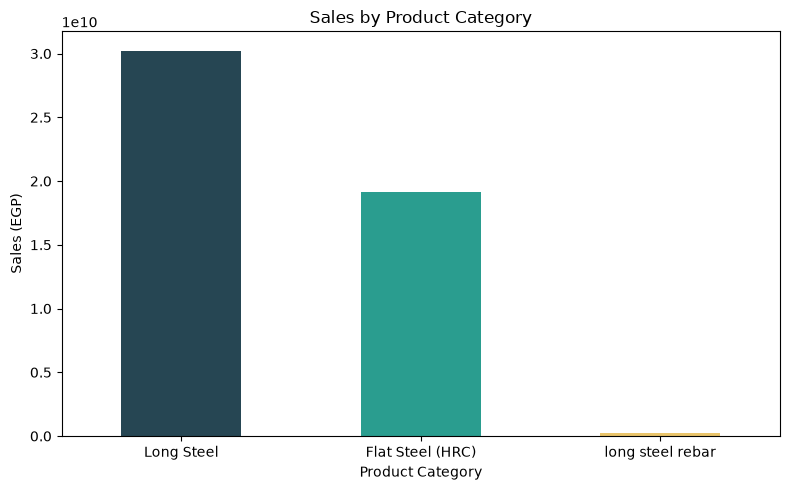

In [36]:
plt.figure(figsize=(8, 5))

sales_by_category.plot(
    kind="bar",
    color=["#264653", "#2A9D8F", "#E9C46A", "#F4A261"]
)

plt.title("Sales by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Sales (EGP)")
plt.xticks(rotation=0)
plt.tight_layout()

plt.show()

### Sales Over Time

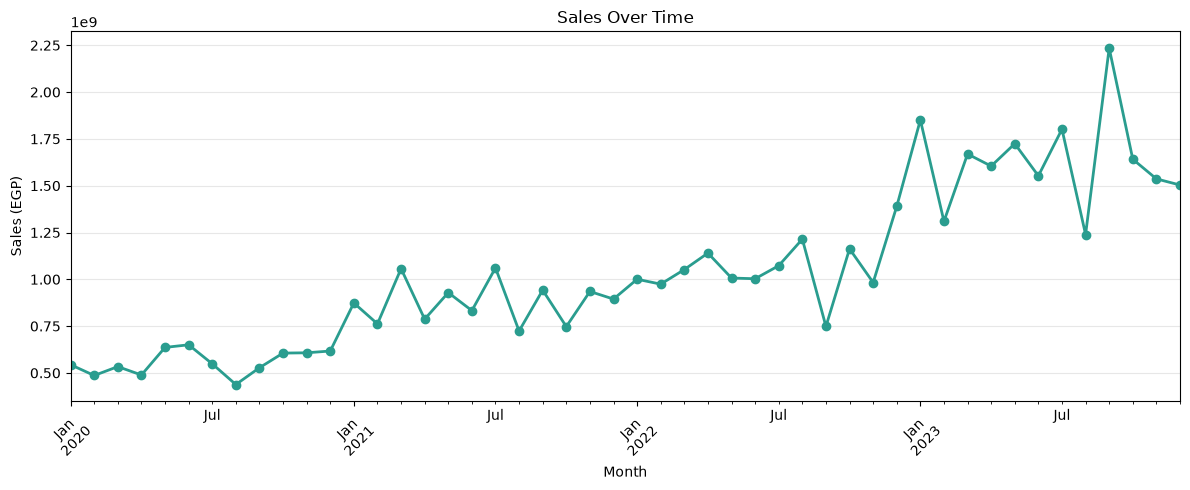

In [37]:
plt.figure(figsize=(12, 5))

monthly_sales.plot(
    kind="line",
    marker="o",
    linewidth=2,
    color="#2A9D8F"
)

plt.title("Sales Over Time")
plt.xlabel("Month")
plt.ylabel("Sales (EGP)")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.show()

### Top 10 Products

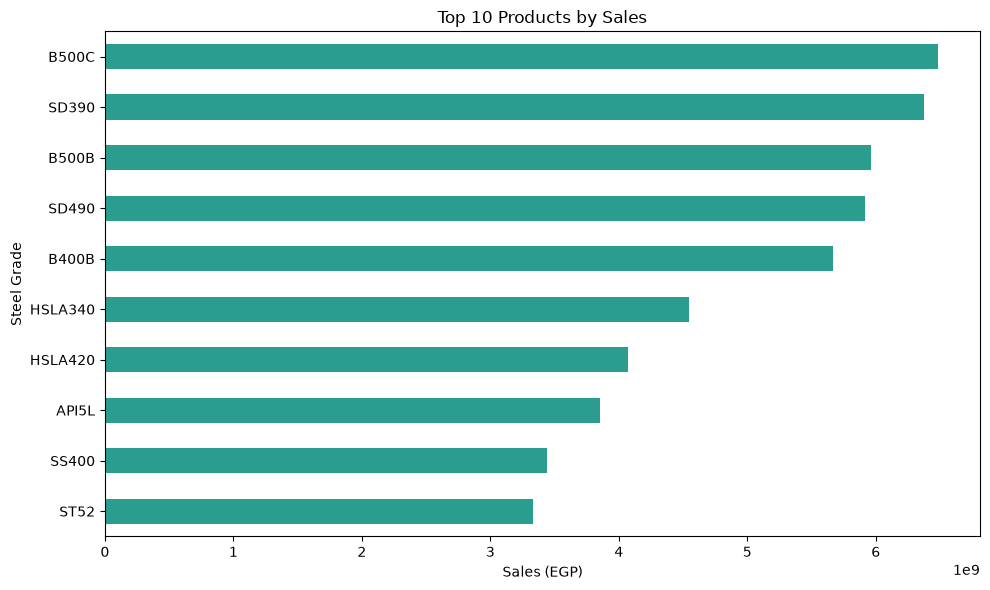

In [38]:
top_10_products = sales_by_product.head(10)

plt.figure(figsize=(10, 6))

top_10_products.sort_values().plot(
    kind="barh",
    color="#2A9D8F"
)

plt.title("Top 10 Products by Sales")
plt.xlabel("Sales (EGP)")
plt.ylabel("Steel Grade")
plt.tight_layout()

plt.show()

### Sales by Region

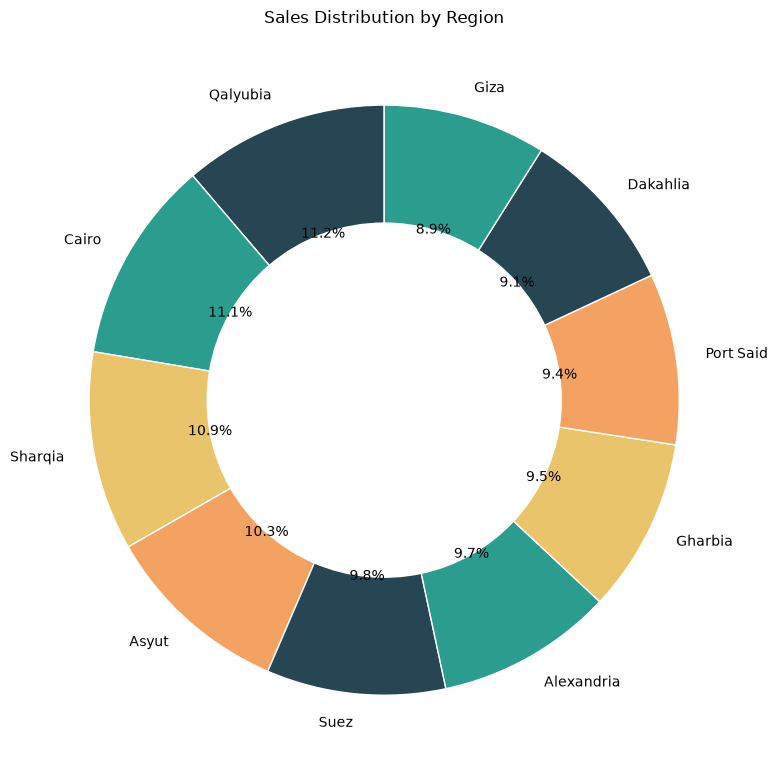

In [39]:
plt.figure(figsize=(8, 8))

plt.pie(
    sales_by_region,
    labels=sales_by_region.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=["#264653", "#2A9D8F", "#E9C46A", "#F4A261"],
    wedgeprops=dict(width=0.4, edgecolor="white")
)

plt.title("Sales Distribution by Region")
plt.tight_layout()

plt.show()

### Business Insights

1. Long Steel was the highest-performing product category, generating the largest share of total sales.

2. B500C was the top-selling product, generating 6.49 billion EGP in sales, indicating strong demand for this steel grade.

3. Qalyubia was the highest-performing region, with sales of approximately 3.89 billion EGP, making it the strongest regional market.

4. September 2023 recorded the highest monthly sales, reaching approximately 2.23 billion EGP, indicating a significant peak in sales activity during this month.

5. Total sales reached approximately 49.65 billion EGP, reflecting a strong overall sales performance across the analyzed period.

# Final Results

- Total Sales: 49,646,540,830 EGP
- Total Net Profit: 18,183.00 Million EGP
- Top Category: Long Steel
- Top-Selling Product: B500C
- Top Region: Qalyubia
- Top Month: September 2023